In [1]:
import pandas as pd

df = pd.read_excel('../data/raw/financial_loan.xlsx')
print(df.shape)
df.head()

(38576, 24)


,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     38576 non-null  int64         
 1   address_state          38576 non-null  object        
 2   application_type       38576 non-null  object        
 3   emp_length             38576 non-null  object        
 4   emp_title              37138 non-null  object        
 5   grade                  38576 non-null  object        
 6   home_ownership         38576 non-null  object        
 7   issue_date             38576 non-null  datetime64[ns]
 8   last_credit_pull_date  38576 non-null  datetime64[ns]
 9   last_payment_date      38576 non-null  datetime64[ns]
 10  loan_status            38576 non-null  object        
 11  next_payment_date      38576 non-null  datetime64[ns]
 12  member_id              38576 non-null  int64         
 13  p

In [3]:
df.isnull().sum()

id                          0
address_state               0
application_type            0
emp_length                  0
emp_title                1438
grade                       0
home_ownership              0
issue_date                  0
last_credit_pull_date       0
last_payment_date           0
loan_status                 0
next_payment_date           0
member_id                   0
purpose                     0
sub_grade                   0
term                        0
verification_status         0
annual_income               0
dti                         0
installment                 0
int_rate                    0
loan_amount                 0
total_acc                   0
total_payment               0
dtype: int64

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate loan IDs:", df['id'].duplicated().sum())

Duplicate rows: 0
Duplicate loan IDs: 0


In [5]:
df[['annual_income', 'dti', 'int_rate', 'loan_amount', 'installment', 'total_payment']].describe()

,annual_income,dti,int_rate,loan_amount,installment,total_payment
count,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.964454e+04,0.133274,0.120488,11296.066855,326.862965,12263.348533
std,6.429368e+04,0.066662,0.037164,7460.746022,209.092000,9051.104777
min,4.000000e+03,0.000000,0.054200,500.000000,15.690000,34.000000
25%,4.150000e+04,0.082100,0.093200,5500.000000,168.450000,5633.000000
50%,6.000000e+04,0.134200,0.118600,10000.000000,283.045000,10042.000000
75%,8.320050e+04,0.185900,0.145900,15000.000000,434.442500,16658.000000
max,6.000000e+06,0.299900,0.245900,35000.000000,1305.190000,58564.000000


In [6]:
print(df['loan_status'].value_counts())
print()
print(df['grade'].value_counts().sort_index())

loan_status
Fully Paid     32145
Charged Off     5333
Current         1098
Name: count, dtype: int64

grade
A     9689
B    11674
C     7904
D     5182
E     2786
F     1028
G      313
Name: count, dtype: int64


In [7]:
clean = df.copy()

# every row is INDIVIDUAL, so this column tells us nothing
clean = clean.drop(columns=['application_type'])

# remove stray spaces in text columns
for col in clean.select_dtypes(include='object').columns:
    clean[col] = clean[col].str.strip()

print(clean.shape)

(38576, 23)


In [8]:
clean['issue_month'] = clean['issue_date'].dt.to_period('M').astype(str)
clean['issue_month_num'] = clean['issue_date'].dt.month

print(clean['issue_month'].value_counts().sort_index())



issue_month
2021-01    2332
2021-02    2279
2021-03    2627
2021-04    2755
2021-05    2911
2021-06    3184
2021-07    3366
2021-08    3441
2021-09    3536
2021-10    3796
2021-11    4035
2021-12    4314
Name: count, dtype: int64


In [9]:
# "36 months" -> 36
clean['term_months'] = clean['term'].str.extract(r'(\d+)')[0].astype(int)

# "10+ years" -> 10, "< 1 year" -> 0
clean['emp_length_years'] = clean['emp_length'].str.extract(r'(\d+)')[0].astype(int)
clean.loc[clean['emp_length'].str.contains('<'), 'emp_length_years'] = 0

print(clean[['term', 'term_months', 'emp_length', 'emp_length_years']].drop_duplicates().sort_values('emp_length_years'))

          term  term_months emp_length  emp_length_years
0    60 months           60   < 1 year                 0
15   36 months           36   < 1 year                 0
961  60 months           60     1 year                 1
16   36 months           36     1 year                 1
33   36 months           36    2 years                 2
994  60 months           60    2 years                 2
967  60 months           60    3 years                 3
5    36 months           36    3 years                 3
960  60 months           60    4 years                 4
2    36 months           36    4 years                 4
962  60 months           60    5 years                 5
13   36 months           36    5 years                 5
20   36 months           36    6 years                 6
972  60 months           60    6 years                 6
979  60 months           60    7 years                 7
40   36 months           36    7 years                 7
978  60 months           60    

In [10]:
# fractions -> percentages (0.15 -> 15)
clean['dti_pct'] = (clean['dti'] * 100).round(2)
clean['int_rate_pct'] = (clean['int_rate'] * 100).round(2)

# loan size compared with yearly income
clean['loan_to_income'] = (clean['loan_amount'] / clean['annual_income']).round(3)

# income bands
clean['income_band'] = pd.cut(
    clean['annual_income'],
    bins=[0, 30000, 50000, 75000, 100000, float('inf')],
    labels=['Under 30K', '30K-50K', '50K-75K', '75K-100K', '100K+']
)

# DTI bands
clean['dti_band'] = pd.cut(
    clean['dti_pct'],
    bins=[0, 10, 15, 20, 25, 30],
    labels=['0-10%', '10-15%', '15-20%', '20-25%', '25-30%'],
    include_lowest=True
)

print(clean['income_band'].value_counts().sort_index())
print()
print(clean['dti_band'].value_counts().sort_index())

income_band
Under 30K     4225
30K-50K      10742
50K-75K      11789
75K-100K      6184
100K+         5636
Name: count, dtype: int64

dti_band
0-10%     12803
10-15%     9653
15-20%     8851
20-25%     6623
25-30%      646
Name: count, dtype: int64


In [11]:
cutoff = clean['annual_income'].quantile(0.99)
clean['income_outlier'] = (clean['annual_income'] > cutoff).astype(int)

print("99th percentile income:", cutoff)
print("Flagged loans:", clean['income_outlier'].sum())

99th percentile income: 235000.0
Flagged loans: 385


In [12]:
regions = {
    'West': ['AK','AZ','CA','CO','HI','ID','MT','NV','NM','OR','UT','WA','WY'],
    'Midwest': ['IL','IN','IA','KS','MI','MN','MO','NE','ND','OH','SD','WI'],
    'South': ['AL','AR','DE','DC','FL','GA','KY','LA','MD','MS','NC','OK','SC','TN','TX','VA','WV'],
    'Northeast': ['CT','ME','MA','NH','NJ','NY','PA','RI','VT'],
}
state_to_region = {s: r for r, states in regions.items() for s in states}
clean['region'] = clean['address_state'].map(state_to_region)

print(clean['region'].value_counts(dropna=False))

region
South        12651
West         11067
Northeast     9459
Midwest       5399
Name: count, dtype: int64


In [13]:
# 1 = Charged Off (bad loan), 0 = Fully Paid, blank = Current (outcome unknown yet)
clean['default_flag'] = clean['loan_status'].map({'Charged Off': 1, 'Fully Paid': 0})

known = clean['default_flag'].notna().sum()
print("Loans with known outcome:", known)
print("Default rate: ", round(clean['default_flag'].mean() * 100, 2), "%")

Loans with known outcome: 37478
Default rate:  14.23 %


In [14]:
clean.to_csv('../data/processed/loans_clean.csv', index=False)
print("Saved!", clean.shape)

Saved! (38576, 35)


EDA


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

   issue_month  loans    funded
0      2021-01   2332  25031650
1      2021-02   2279  24647825
2      2021-03   2627  28875700
3      2021-04   2755  29800800
4      2021-05   2911  31738350
5      2021-06   3184  34161475
6      2021-07   3366  35813900
7      2021-08   3441  38149600
8      2021-09   3536  40907725
9      2021-10   3796  44893800
10     2021-11   4035  47754825
11     2021-12   4314  53981425


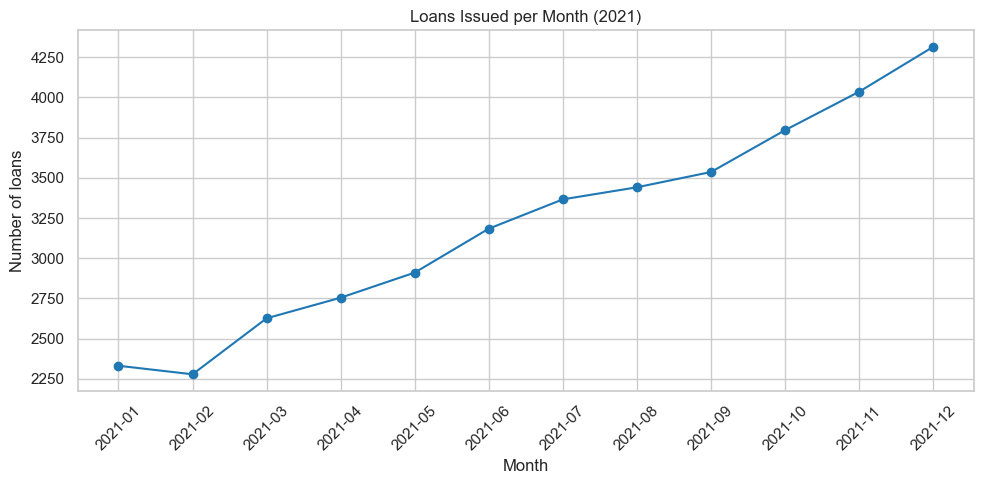

In [17]:
monthly = clean.groupby('issue_month').agg(loans=('id', 'count'), funded=('loan_amount', 'sum')).reset_index()
print(monthly)

plt.figure()
plt.plot(monthly['issue_month'], monthly['loans'], marker='o', color='#1f77b4')
plt.title('Loans Issued per Month (2021)')
plt.xlabel('Month')
plt.ylabel('Number of loans')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/figures/01_monthly_loans.png', dpi=150)
plt.show()

grade
A     5.7
B    11.8
C    16.6
D    21.6
E    26.5
F    32.5
G    33.1
Name: default_flag, dtype: float64


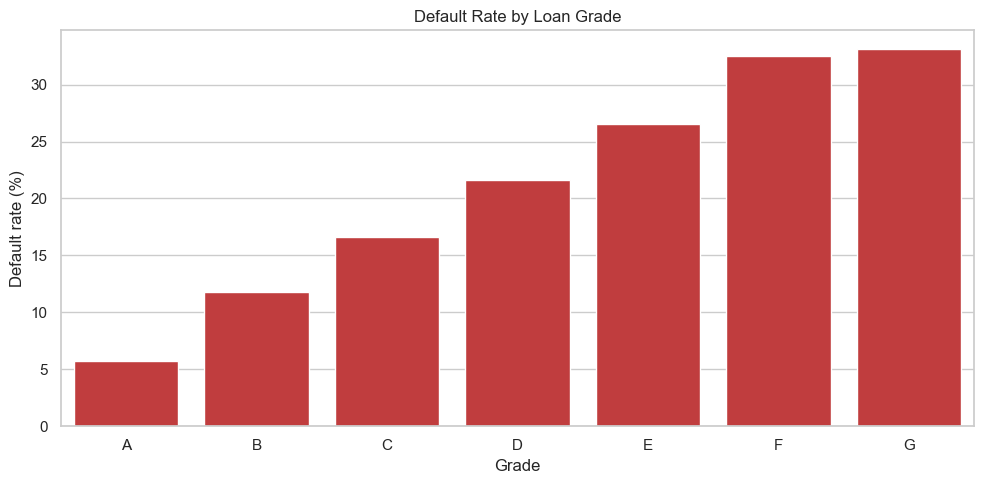

In [18]:
by_grade = (clean.groupby('grade')['default_flag'].mean() * 100).round(1)
print(by_grade)

plt.figure()
sns.barplot(x=by_grade.index, y=by_grade.values, color='#d62728')
plt.title('Default Rate by Loan Grade')
plt.xlabel('Grade')
plt.ylabel('Default rate (%)')
plt.tight_layout()
plt.savefig('../reports/figures/02_default_by_grade.png', dpi=150)
plt.show()

purpose
wedding                9.5
major purchase         9.9
credit card           10.4
car                   10.7
home improvement      11.8
vacation              14.4
Debt consolidation    15.0
moving                15.2
medical               15.3
other                 15.8
educational           15.9
house                 16.2
renewable_energy      18.3
small business        26.7
Name: default_flag, dtype: float64


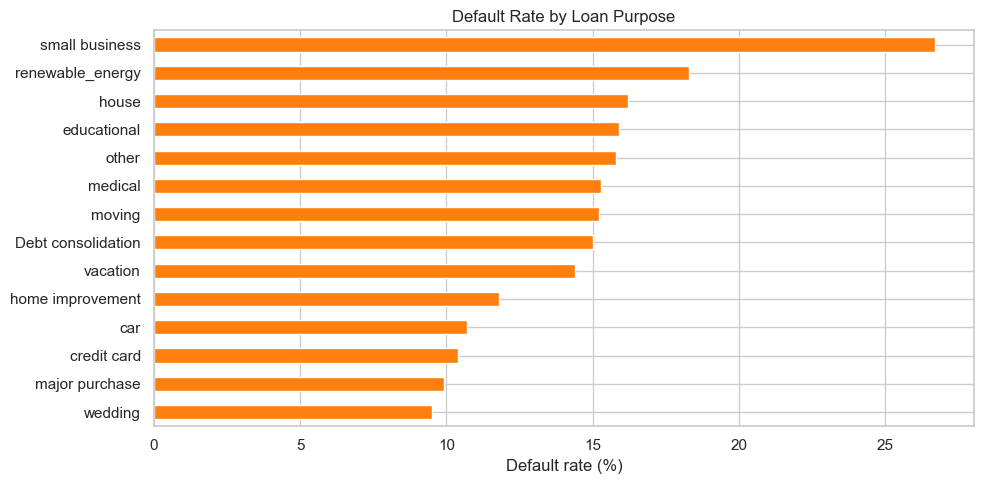

In [19]:
by_purpose = (clean.groupby('purpose')['default_flag'].mean() * 100).round(1).sort_values()
print(by_purpose)

plt.figure()
by_purpose.plot(kind='barh', color='#ff7f0e')
plt.title('Default Rate by Loan Purpose')
plt.xlabel('Default rate (%)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../reports/figures/03_default_by_purpose.png', dpi=150)
plt.show()

dti_band
0-10%     12.3
10-15%    14.3
15-20%    15.4
20-25%    16.5
25-30%    13.3
Name: default_flag, dtype: float64


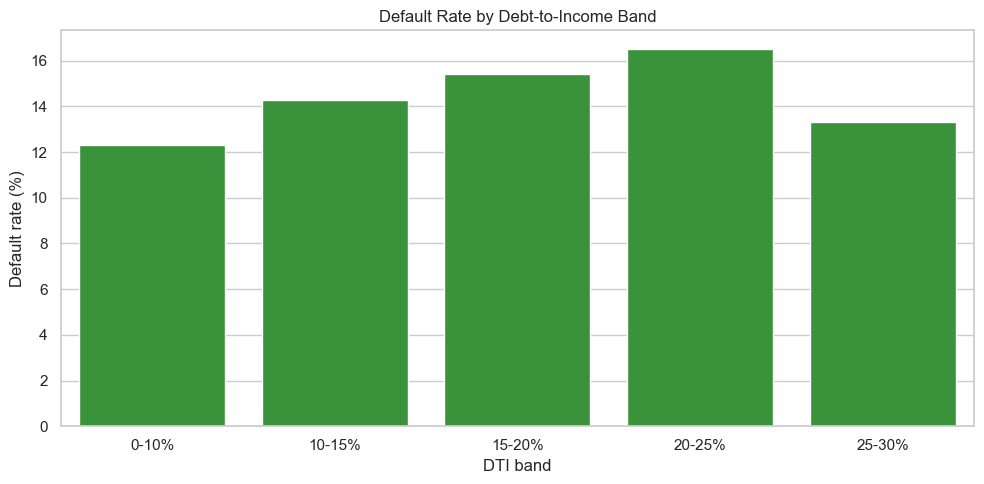

In [20]:
by_dti = (clean.groupby('dti_band', observed=True)['default_flag'].mean() * 100).round(1)
print(by_dti)

plt.figure()
sns.barplot(x=by_dti.index.astype(str), y=by_dti.values, color='#2ca02c')
plt.title('Default Rate by Debt-to-Income Band')
plt.xlabel('DTI band')
plt.ylabel('Default rate (%)')
plt.tight_layout()
plt.savefig('../reports/figures/04_default_by_dti.png', dpi=150)
plt.show()

In [21]:
by_term = (clean.groupby('term_months')['default_flag'].mean() * 100).round(1)
print(by_term)

term_months
36    10.7
60    25.0
Name: default_flag, dtype: float64
